
# Group 2 – Problem Analysis Workshop B

## Police-Reported Cybercrime in Canada
### K-Means Clustering Analysis

**Course:** PROG8431 – Data Analysis, Mathematics, Modeling and Algorithms

**Workshop:** Problem Analysis Workshop B

### Team Members

| Student Name | Student ID |
|---|---|
| Senay Teweldebrhan | 9120588 |
| Juan Camilo Chirivi | 9115141 |
| Zeynep Ozdemir | 9045142 |

### Project Objective

The objective of this workshop is to apply K-Means clustering to police-reported cybercrime data in Canada.

We aim to identify groups of Canadian metropolitan areas with similar cybercrime rates, explore patterns in the data, and interpret the characteristics of each cluster.


## 1. Dataset Overview
We use Statistics Canada police-reported cybercrime data. The unit of analysis is one full Census Metropolitan Area (CMA). The data reports cybercrime incidents per 100,000 population.

**Research question:** Which Canadian CMAs have the highest recent increases in police-reported cybercrime rates, and what groups emerge when we compare their 2025 rates with their percentage changes from 2023 to 2025?

We use historical rates to engineer one growth feature. K-Means is an **unsupervised clustering method**, not a time-series forecasting model.

## 2. Setup and Configuration
Import the libraries for data preparation, descriptive analysis, plotting, and K-Means. The standardization function and K-Means configuration below follow the Week 7 demonstration.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans


## 3. Load and Inspect the Dataset

We load the Statistics Canada cybercrime dataset and inspect its size, columns, available years, statistics, and first five rows to understand its structure.

In [4]:
# Use the project data folder when available; otherwise use the notebook folder.
candidates = [Path("data/35100002.csv"), Path("../data/35100002.csv"), Path("35100002(1).csv")]
file_path = next((path for path in candidates if path.exists()), None)
if file_path is None:
    raise FileNotFoundError("Place 35100002.csv in the notebook folder or its data/ subfolder.")
raw = pd.read_csv(file_path, low_memory=False)
print("Dataset shape:", raw.shape)
print("Columns:", list(raw.columns))
print("Years:", sorted(raw["REF_DATE"].unique()))
print("Statistics:", raw["Statistics"].unique())
display(raw.head())

Dataset shape: (1356, 15)
Columns: ['REF_DATE', 'GEO', 'DGUID', 'Statistics', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']
Years: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Statistics: <StringArray>
['Number of cybercrime incidents', 'Rate per 100,000 population']
Length: 2, dtype: str


,REF_DATE,GEO,DGUID,Statistics,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,2014,Total police-reported cybercrime,NaN,Number of cybercrime incidents,Number,223,units,0,v116321076,1.1,15184.0,NaN,NaN,NaN,0
1,2014,Total police-reported cybercrime,NaN,"Rate per 100,000 population","Rate per 100,000 population",265,units,0,v116321077,1.2,47.7,NaN,NaN,NaN,1
2,2014,Total Non-Census metropolitan area,NaN,Number of cybercrime incidents,Number,223,units,0,v116321078,2.1,5075.0,NaN,NaN,NaN,0
3,2014,Total Non-Census metropolitan area,NaN,"Rate per 100,000 population","Rate per 100,000 population",265,units,0,v116321079,2.2,58.1,NaN,NaN,NaN,1
4,2014,Total Census metropolitan area,NaN,Number of cybercrime incidents,Number,223,units,0,v116321080,3.1,10109.0,NaN,NaN,NaN,0


## 4. Data Cleaning and Preparation
Select the police-reported cybercrime **rate per 100,000 people** for 2023 and 2025. Retain full Census Metropolitan Areas (CMAs), excluding separate provincial portions of a CMA. Reshape the table so each CMA has one row and one rate for each year. Check for missing and duplicate records before computing growth.

Using rates rather than incident totals improves comparisons among CMAs with different population sizes.

In [5]:
data = raw.copy()
data["REF_DATE"] = pd.to_numeric(data["REF_DATE"], errors="coerce")
data["VALUE"] = pd.to_numeric(data["VALUE"], errors="coerce")

rates = data.loc[
    data["REF_DATE"].isin([2023, 2025]) &
    data["Statistics"].eq("Rate per 100,000 population")
].copy()

is_cma = rates["GEO"].str.contains(r"\[\d{5}\]", regex=True, na=False)
is_split_part = rates["GEO"].str.contains(" part ", case=False, na=False)
rates = rates.loc[is_cma & ~is_split_part].copy()

# Validate that each CMA/year corresponds to one rate before reshaping.
duplicate_keys = rates.duplicated(subset=["GEO", "REF_DATE"], keep=False)
print("Duplicate CMA-year rows:", int(duplicate_keys.sum()))
if duplicate_keys.any():
    raise ValueError("Duplicate CMA-year rates found; inspect the source before pivoting.")

wide = rates.pivot(index="GEO", columns="REF_DATE", values="VALUE")
wide = wide.rename(columns={2023: "Rate_2023", 2025: "Rate_2025"})
wide = wide.dropna(subset=["Rate_2023", "Rate_2025"]).copy()
print("CMAs with both years:", len(wide))
print("Missing values:", wide.isna().sum().to_dict())
display(wide.head())

Duplicate CMA-year rows: 0
CMAs with both years: 39
Missing values: {'Rate_2023': 0, 'Rate_2025': 0}


REF_DATE,Rate_2023,Rate_2025
GEO,,
"Abbotsford-Mission, British Columbia [59932]",852.0,893.6
"Barrie, Ontario [35568]",213.4,114.8
"Belleville-Quinte West, Ontario [35522]",114.2,113.3
"Brantford, Ontario [35543]",420.7,430.6
"Calgary, Alberta [48825]",213.6,203.0


## 5. Why K-Means Clustering?
Workshop A examined the dataset using descriptive statistics and comparisons. Workshop B uses unsupervised learning groups CMAs with similar **current reported cybercrime rates** and **recent percentage changes**,  without assigning groups in advance. This may distinguish high-rate areas from rapidly increasing areas.



## 6. Two Features Used to Define the Clusters (Step 7)

1. **Rate_2025:** Police-reported cybercrime incidents per 100,000 population in 2025. This measures the latest reported rate.
2. **Growth_2023_2025_pct:** Total percentage change in the rate between 2023 and 2025. This measures how rapidly the reported rate changed over that period, relative to its 2023 starting value.

\[
\text{Growth}_{2023-2025}(\%)=\frac{R_{2025}-R_{2023}}{R_{2023}}\times100
\]


**Why these two variables?** One captures the current level; the other captures change over time. These features can help distinguish consistently high-rate areas from areas with faster recent increases. We avoid total incident counts because CMA populations differ.

**Caution:** Growth is undefined when the 2023 rate is zero. Small baseline rates can also create unusually large percentages. We inspect these cases before clustering. Both features come from the same underlying rates and may still be correlated.

In [6]:
# Calculate the two-year percentage change after checking the baseline.
zero_or_negative = wide["Rate_2023"] <= 0
print("CMAs with nonpositive 2023 rates:", int(zero_or_negative.sum()))
if zero_or_negative.any():
    display(wide.loc[zero_or_negative])
    raise ValueError("Growth is undefined for a zero baseline; decide how to handle these CMAs.")

wide["Growth_2023_2025_pct"] = (
    (wide["Rate_2025"] - wide["Rate_2023"]) / wide["Rate_2023"] * 100
)
features = wide[["Rate_2025", "Growth_2023_2025_pct"]].copy()
print("CMAs included:", len(features))
display(features.head().round(2))

CMAs with nonpositive 2023 rates: 0
CMAs included: 39


REF_DATE,Rate_2025,Growth_2023_2025_pct
GEO,,
"Abbotsford-Mission, British Columbia [59932]",893.6,4.88
"Barrie, Ontario [35568]",114.8,-46.20
"Belleville-Quinte West, Ontario [35522]",113.3,-0.79
"Brantford, Ontario [35543]",430.6,2.35
"Calgary, Alberta [48825]",203.0,-4.96


## 7. Explore the Two Variables Before Standardization (Step 8)

`describe()` summarizes the distributions; the correlation measures their linear relationship. Histograms show skewness, while boxplots help flag unusually high or low values. We inspect the growth extremes because percentage changes can be large when the starting rate is small. We do **not** remove outliers automatically: they may represent meaningful CMAs.

REF_DATE,Rate_2025,Growth_2023_2025_pct
count,39.00,39.00
mean,303.60,-2.29
std,179.89,24.98
min,69.00,-46.20
25%,182.65,-19.45
50%,270.70,-5.06
75%,368.85,5.46
max,893.60,60.50


Correlation between features: 0.054
Duplicate CMA names: 0

Five largest increases:


REF_DATE,Rate_2023,Rate_2025,Growth_2023_2025_pct
GEO,,,
"Guelph, Ontario [35550]",237.2,380.7,60.50
"Saguenay, Quebec [24408]",46.2,69.0,49.35
"Thunder Bay, Ontario [35595]",348.0,510.0,46.55
"Regina, Saskatchewan [47705]",126.0,174.5,38.49
"Hamilton, Ontario [35537]",179.4,242.3,35.06



Five largest decreases:


REF_DATE,Rate_2023,Rate_2025,Growth_2023_2025_pct
GEO,,,
"Barrie, Ontario [35568]",213.4,114.8,-46.20
"Greater Sudbury, Ontario [35580]",415.2,274.1,-33.98
"Kamloops, British Columbia [59925]",524.6,350.7,-33.15
"Kelowna, British Columbia [59915]",489.4,331.5,-32.26
"Victoria, British Columbia [59935]",593.7,420.3,-29.21


C:\Users\Admin\AppData\Local\Temp\ipykernel_9528\660892204.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, j].boxplot(features[col], vert=False)
C:\Users\Admin\AppData\Local\Temp\ipykernel_9528\660892204.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, j].boxplot(features[col], vert=False)


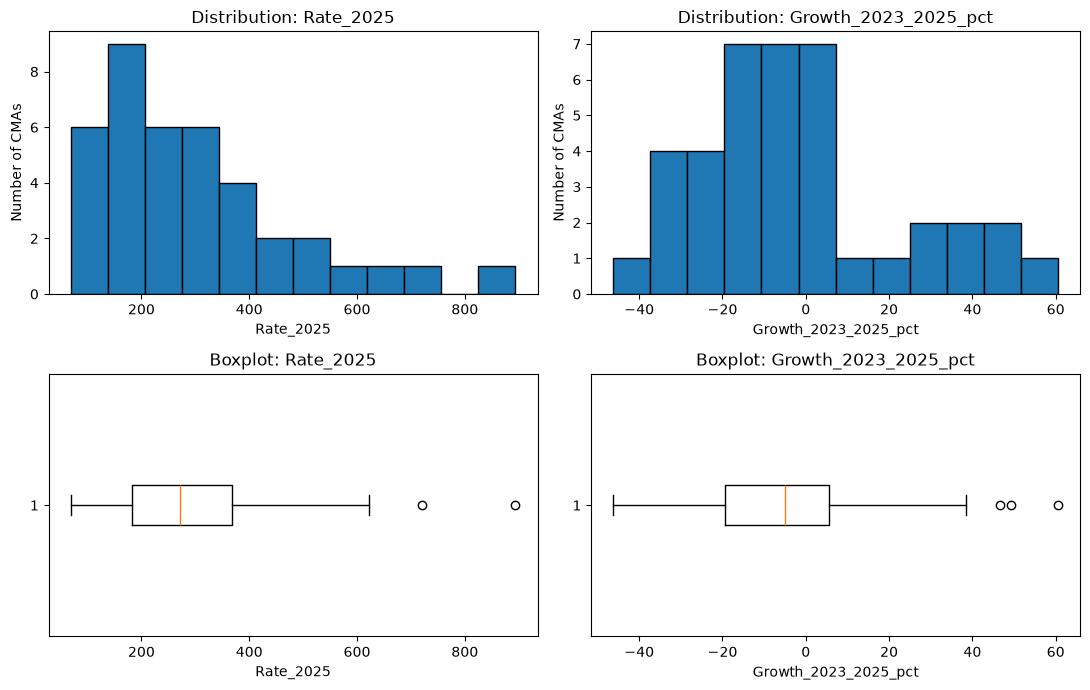

In [7]:
display(features.describe().round(2))
print("Correlation between features:", round(features.corr().iloc[0, 1], 3))
print("Duplicate CMA names:", int(wide.index.duplicated().sum()))
print("\nFive largest increases:")
display(wide[["Rate_2023", "Rate_2025", "Growth_2023_2025_pct"]]
        .sort_values("Growth_2023_2025_pct", ascending=False).head().round(2))
print("\nFive largest decreases:")
display(wide[["Rate_2023", "Rate_2025", "Growth_2023_2025_pct"]]
        .sort_values("Growth_2023_2025_pct").head().round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, col in enumerate(features.columns):
    axes[0, j].hist(features[col], bins=12, edgecolor="black")
    axes[0, j].set(title=f"Distribution: {col}", xlabel=col, ylabel="Number of CMAs")
    axes[1, j].boxplot(features[col], vert=False)
    axes[1, j].set(title=f"Boxplot: {col}", xlabel=col)
plt.tight_layout()
plt.show()

## 8. Standardize the Variables (Step 9)

The professor demonstrated two functions: `sta01()` for minimum–maximum scaling and `stamn()` for **Z-score standardization**. We choose `stamn()` to express both variables in standard-deviation units, since their original units differ (incidents per 100,000 versus percentage change).

\[z=\frac{x-\bar{x}}{s}\]

Here, \(\bar{x}\) is the sample mean and \(s\) is the sample standard deviation. A Z-score of +2 means an observation is two standard deviations above the mean. This matters because K-Means uses Euclidean distance; without scaling, the variable with the larger numerical spread may dominate the clusters.

We standardize **only the two selected numeric features**, not CMA names.

In [8]:
# The same two functions used in the professor's Week 7 demonstration.
def sta01(x):
    return (x - x.min()) / (x.max() - x.min())

def stamn(x):
    return (x - x.mean()) / x.std()

X = features.apply(stamn)
print("Standardized means (approximately 0):")
print(X.mean().round(6))
print("Standardized sample SDs (approximately 1):")
print(X.std().round(6))
display(X.head().round(3))

Standardized means (approximately 0):
REF_DATE
Rate_2025               0.0
Growth_2023_2025_pct    0.0
dtype: float64
Standardized sample SDs (approximately 1):
REF_DATE
Rate_2025               1.0
Growth_2023_2025_pct    1.0
dtype: float64


REF_DATE,Rate_2025,Growth_2023_2025_pct
GEO,,
"Abbotsford-Mission, British Columbia [59932]",3.280,0.287
"Barrie, Ontario [35568]",-1.050,-1.758
"Belleville-Quinte West, Ontario [35522]",-1.058,0.060
"Brantford, Ontario [35543]",0.706,0.186
"Calgary, Alberta [48825]",-0.559,-0.107


## 9. Generate K-Means Models and Examine the Elbow (Step 10)

Following the Week 7 notebook, we fit K-Means for **K = 1 through 7**, using `max_iter=10`, `n_init=10`, and `random_state=123`.

- **K:** Number of clusters (groups).
- **Centroid:** Mean position of observations assigned to a cluster.
- **Within-cluster sum of squares (WSS):** Sum of squared distances from each observation to its cluster centroid; in scikit-learn this is `inertia_`.
- **Total sum of squares (TSS):** Total squared variation around the overall feature means.
- **Between-cluster sum of squares (BSS):** `TSS − WSS`.

As K increases, WSS cannot increase for an optimal solution and generally decreases in practice. We inspect where the improvement begins to level off (the **elbow**), rather than choosing K solely because it is larger. The final choice and interpretation belong to the team in Step 11.


K = 1
Centroids (standardized units):
[[0. 0.]]
Cluster sizes: [39]
TSS=76.000; WSS=76.000; BSS=0.000

K = 2
Centroids (standardized units):
[[-0.402 -0.495]
 [ 0.805  0.99 ]]
Cluster sizes: [26, 13]
TSS=76.000; WSS=44.266; BSS=31.734

K = 3
Centroids (standardized units):
[[-0.377 -0.545]
 [ 1.8    0.085]
 [-0.17   1.641]]
Cluster sizes: [25, 6, 8]
TSS=76.000; WSS=23.765; BSS=52.235

K = 4
Centroids (standardized units):
[[-0.084 -0.945]
 [-0.048  1.765]
 [-0.721 -0.044]
 [ 1.8    0.085]]
Cluster sizes: [13, 7, 13, 6]
TSS=76.000; WSS=16.205; BSS=59.795

K = 5
Centroids (standardized units):
[[-0.69  -0.21 ]
 [ 1.8    0.085]
 [-0.702  1.46 ]
 [ 0.02  -0.973]
 [ 0.717  1.941]]
Cluster sizes: [14, 6, 5, 11, 3]
TSS=76.000; WSS=12.860; BSS=63.140

K = 6
Centroids (standardized units):
[[ 0.717  1.941]
 [-0.084 -0.945]
 [ 2.798 -0.032]
 [-0.702  1.46 ]
 [-0.695 -0.112]
 [ 1.3    0.144]]
Cluster sizes: [3, 13, 2, 5, 12, 4]
TSS=76.000; WSS=9.852; BSS=66.148

K = 7
Centroids (standardized uni

,K,TSS,WSS,BSS,Cluster sizes
0,1,76.0,76.000,0.000,[39]
1,2,76.0,44.266,31.734,"[26, 13]"
2,3,76.0,23.765,52.235,"[25, 6, 8]"
3,4,76.0,16.205,59.795,"[13, 7, 13, 6]"
4,5,76.0,12.860,63.140,"[14, 6, 5, 11, 3]"
5,6,76.0,9.852,66.148,"[3, 13, 2, 5, 12, 4]"
6,7,76.0,8.246,67.754,"[4, 10, 2, 4, 11, 3, 5]"


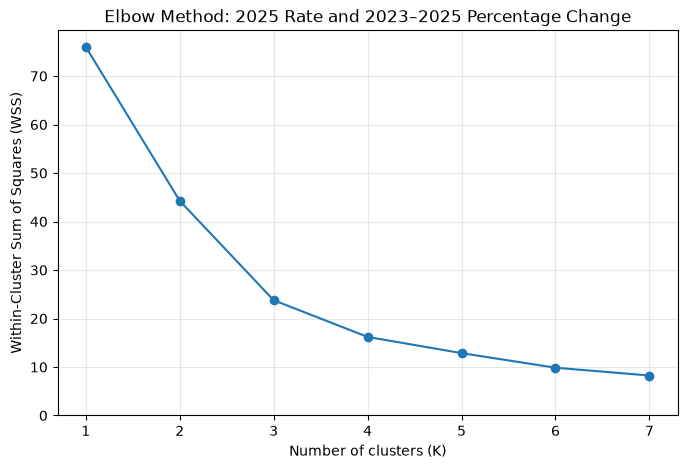

In [9]:
maxk = 7
nk = range(1, maxk + 1)
wss = np.zeros(maxk)
cluster_models = {}
model_summary = []

# Total SS: square the deviations of each column from its own mean.
total_ss = ((X - X.mean()) ** 2).to_numpy().sum()

for k in nk:
    km = KMeans(n_clusters=k, max_iter=10, n_init=10, random_state=123)
    km.fit(X)
    cluster_models[k] = km

    within_ss = km.inertia_
    between_ss = total_ss - within_ss
    sizes = np.bincount(km.labels_, minlength=k)
    wss[k - 1] = within_ss
    model_summary.append({"K": k, "TSS": total_ss,
                          "WSS": within_ss, "BSS": between_ss,
                          "Cluster sizes": str(sizes.tolist())})

    print(f"\nK = {k}")
    print("Centroids (standardized units):")
    print(np.round(km.cluster_centers_, 3))
    print("Cluster sizes:", sizes.tolist())
    print(f"TSS={total_ss:.3f}; WSS={within_ss:.3f}; BSS={between_ss:.3f}")

results = pd.DataFrame(model_summary)
display(results.round(3))

plt.figure(figsize=(8, 5))
plt.plot(list(nk), wss, marker="o")
plt.title("Elbow Method: 2025 Rate and 2023–2025 Percentage Change")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WSS)")
plt.xticks(list(nk))
plt.ylim(bottom=0)
plt.grid(alpha=0.3)
plt.show()

## 10. Handoff to Juan (Step 11)

